# NewsBot Intelligence System

**ITAI 2373 — Midterm Project**

This notebook develops a news-article analysis pipeline that combines text preprocessing, TF-IDF, part-of-speech tagging, dependency parsing, sentiment analysis, multi-class classification, and named entity recognition. It also compares classification models and exports figures and summary results.

**Dataset:** [BBC News Classification](https://www.kaggle.com/competitions/learn-ai-bbc/data), using the labeled training CSV. The five categories are business, entertainment, politics, sport, and tech.

**Method:** Classification is evaluated using a stratified train/test split. Computationally expensive linguistic analysis uses a smaller stratified sample. Model evaluation, preprocessing choices, and limitations are documented in the relevant sections.

## 1. Business context

The system is intended for news editors, media analysts, and corporate communications teams. It groups articles by topic, identifies named entities, and summarizes lexical sentiment to support news monitoring and initial triage.

**Scope:** Classification and sentiment predictions are imperfect. Entity co-mentions show that names appeared in the same article, not that a verified relationship exists between them. Findings should be reviewed before operational use.

In [1]:
# Project identification
STUDENT_FULL_NAME = "Zain Ahmed"
GROUP_NAME_OR_NUMBER = "Individual"
GITHUB_URL = "https://github.com/zainahm713/ITAI2373-Portfolio"


In [2]:
# Colab environment setup (first run may ask for runtime restart if packages change).
%pip -q install "spacy>=3.7,<4" "scikit-learn>=1.3,<2" "nltk>=3.8,<4" "pandas>=2,<4" "matplotlib>=3.7,<4" "joblib>=1.3,<2" "reportlab>=4,<5" "pillow>=9,<12" "tabulate>=0.9,<1" "networkx>=3,<5"
!python -m spacy download en_core_web_sm -q

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.0/2.0 MB 6.6 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.8/12.8 MB 32.7 MB/s eta 0:00:00
✔ Download and installation successful
You can now load the package via spacy.load('en_core_web_sm')
⚠ Restart to reload dependencies
If you are in a Jupyter or Colab notebook, you may need to restart Python in
order to load all the package's dependencies. You can do this by selecting the
'Restart kernel' or 'Restart runtime' option.


In [3]:
from pathlib import Path
from collections import Counter
from itertools import combinations
import json, re, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import nltk, spacy, joblib

from nltk.sentiment import SentimentIntensityAnalyzer
from sklearn.model_selection import train_test_split, StratifiedKFold, GridSearchCV
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.naive_bayes import MultinomialNB
from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC
from sklearn.metrics import accuracy_score, f1_score, classification_report, ConfusionMatrixDisplay

nltk.download("vader_lexicon", quiet=True)
nlp = spacy.load("en_core_web_sm")
sia = SentimentIntensityAnalyzer()
OUT = Path("results"); OUT.mkdir(exist_ok=True)
RANDOM_STATE = 42
print("Libraries loaded. spaCy:", spacy.__version__)

Libraries loaded. spaCy: 3.8.16


## Dataset provenance and validation

Data are drawn from the labeled BBC News Classification training corpus. At least 500 substantive English-language articles across four or more categories are required for this analysis. Only labeled records are included in supervised evaluation.

In [4]:
from google.colab import files

print("Select labeled data (BBC News Train.csv)")
uploaded = files.upload()
csv_files = [name for name in uploaded if name.lower().endswith(".csv")]
if not csv_files:
    raise ValueError("No .csv uploaded. Upload the labeled BBC News Train.csv, not the unlabeled test set.")
DATA_PATH = csv_files[0]
print("Selected:", DATA_PATH)

Select labeled data (BBC News Train.csv)


Saving BBC News Train.csv to BBC News Train.csv
Selected: BBC News Train.csv


Usable articles: 1440 of 1490. Categories: 5
category
sport            342
business         335
politics         266
entertainment    263
tech             234
Name: count, dtype: int64


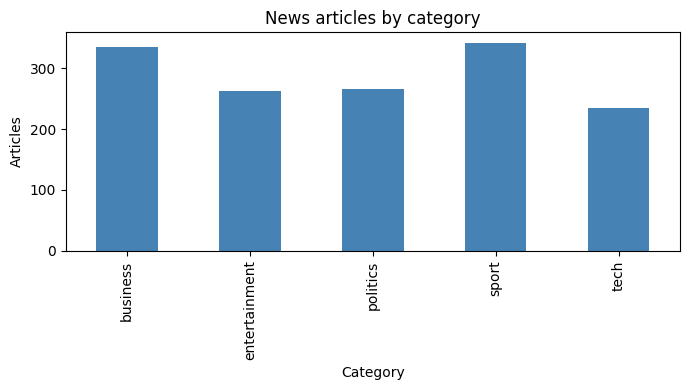

In [5]:
# Change these only if your approved dataset has unusual column names.
TEXT_COLUMN = None
LABEL_COLUMN = None
MAX_ROWS = 2000

raw = pd.read_csv(DATA_PATH)
column_map = {c.lower().strip(): c for c in raw.columns}
def pick_column(explicit, candidates):
    if explicit:
        if explicit not in raw.columns:
            raise KeyError(f"Column '{explicit}' not found. Available: {list(raw.columns)}")
        return explicit
    for key in candidates:
        if key in column_map:
            return column_map[key]
    raise ValueError(f"Could not identify column from {list(raw.columns)}. Specify TEXT_COLUMN/LABEL_COLUMN.")
text_col = pick_column(TEXT_COLUMN, ["text", "article", "content", "description"])
label_col = pick_column(LABEL_COLUMN, ["category", "label", "class"])

df = raw[[text_col, label_col]].rename(columns={text_col: "content", label_col: "category"}).copy()
before = len(df)
df = df.dropna(subset=["content", "category"])
df["content"] = df["content"].astype(str).str.strip()
df["category"] = df["category"].astype(str).str.strip().str.lower()
df = df[(df["content"].str.len() >= 150) & (df["category"].str.len() > 0)]
df = df.drop_duplicates(subset=["content"]).reset_index(drop=True)
if len(df) > MAX_ROWS:
    df, _ = train_test_split(df, train_size=MAX_ROWS, stratify=df["category"],
                             random_state=RANDOM_STATE)
    df = df.reset_index(drop=True)
print(f"Usable articles: {len(df)} of {before}. Categories: {df['category'].nunique()}")
print(df["category"].value_counts())
if len(df) < 500 or df["category"].nunique() < 4:
    raise ValueError("Requirements not met: at least 500 substantial articles and 4 categories.")
df[["content","category"]].to_csv(OUT/"dataset_prepared.csv", index=False)
ax = df["category"].value_counts().sort_index().plot(kind="bar", title="News articles by category",
                                                       color="steelblue", figsize=(7,4))
ax.set_ylabel("Articles"); ax.set_xlabel("Category")
plt.tight_layout(); plt.savefig(OUT/"01_category_counts.png", dpi=140); plt.show()

## Module 2 — Text preprocessing

Pipeline: whitespace / URL cleanup → spaCy tokenization → remove punctuation, stop words and numbers → lemmatize → lowercase.

The `en_core_web_sm` pipeline runs without dependency parsing or NER during cleaning to improve speed. We retain original text separately for entity and syntax analysis.

In [6]:
def normalize_whitespace_and_urls(text):
    text = re.sub(r"https?://\S+|www\.\S+", " ", str(text))
    text = re.sub(r"\s+", " ", text).strip()
    return text

df["normalized"] = df["content"].map(normalize_whitespace_and_urls)
def to_lemmas(doc):
    return " ".join(t.lemma_.lower() for t in doc if t.is_alpha
                    and not t.is_stop and len(t.lemma_) >= 3)

# For very long article texts, truncate the linguistic processing to stay in Colab's free limits.
# Record this decision in the limitations section of the report.
LINGUISTIC_CHAR_LIMIT = 5000
with nlp.select_pipes(disable=["parser", "ner"]):
    processed_docs = nlp.pipe(
        (t[:LINGUISTIC_CHAR_LIMIT] for t in df["normalized"]),
        batch_size=24
    )
    df["cleaned"] = [to_lemmas(doc) for doc in processed_docs]
if df["cleaned"].str.len().eq(0).any():
    df = df[df["cleaned"].str.len().gt(0)].reset_index(drop=True)
    print("Removed rows that became empty after preprocessing.")
assert len(df) >= 500 and df["category"].nunique() >= 4, "Dataset too small after cleaning"
print("Original excerpt:", df.loc[0,"content"][:220])
print("Lemmatized excerpt:", df.loc[0,"cleaned"][:220])
df[["category","cleaned"]].to_csv(OUT/"cleaned_articles.csv", index=False)

Original excerpt: worldcom ex-boss launches defence lawyers defending former worldcom chief bernie ebbers against a battery of fraud charges have called a company whistleblower as their first witness.  cynthia cooper  worldcom s ex-head o
Lemmatized excerpt: worldcom boss launch defence lawyer defend worldcom chief bernie ebber battery fraud charge call company whistleblow witness cynthia cooper worldcom head internal accounting alert director irregular accounting practice t


## Module 3 — TF-IDF and feature analysis

We split before fitting the vectorizer to prevent information leakage from the held-out test set. TF-IDF is fit **only on training articles**.

,category,term,mean_tfidf
0,business,say,0.039058
1,business,firm,0.036325
2,business,company,0.034772
3,business,market,0.033916
4,business,year,0.030194
5,business,share,0.028636
6,business,rise,0.027919
7,business,economy,0.027748
12,entertainment,film,0.064818
13,entertainment,star,0.045733


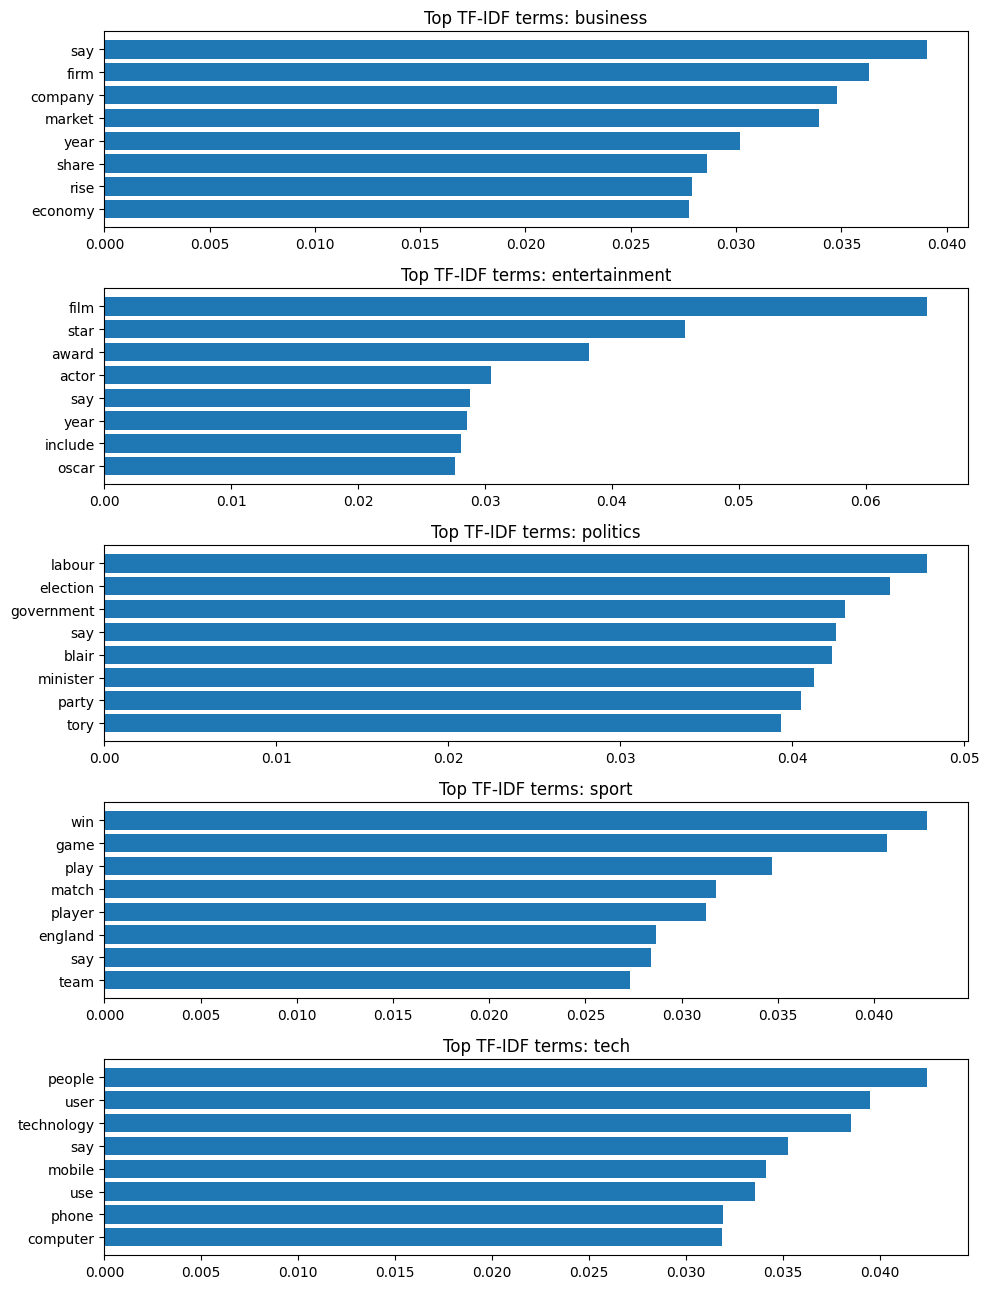

In [7]:
X_train, X_test, y_train, y_test = train_test_split(
    df["cleaned"], df["category"], test_size=0.25,
    random_state=RANDOM_STATE, stratify=df["category"]
)
vectorizer = TfidfVectorizer(
    max_features=7000, min_df=2, max_df=0.95,
    ngram_range=(1, 2), sublinear_tf=True
)
Xtr = vectorizer.fit_transform(X_train)
Xte = vectorizer.transform(X_test)
terms = np.asarray(vectorizer.get_feature_names_out())
feature_rows = []
for cat in sorted(y_train.unique()):
    mean_vector = np.asarray(Xtr[np.asarray(y_train == cat)].mean(axis=0)).ravel()
    top_idx = np.argsort(mean_vector)[-12:][::-1]
    feature_rows.extend({"category":cat, "term":terms[i], "mean_tfidf":float(mean_vector[i])}
                        for i in top_idx)
feature_df = pd.DataFrame(feature_rows)
feature_df.to_csv(OUT/"top_tfidf_terms.csv", index=False)
display(feature_df.groupby("category").head(8))
cats = sorted(y_train.unique())
fig, axes = plt.subplots(len(cats), 1, figsize=(10, max(2.6*len(cats), 7)))
for ax, cat in zip(np.ravel(axes), cats):
    top = feature_df[feature_df.category == cat].head(8).sort_values("mean_tfidf")
    ax.barh(top["term"], top["mean_tfidf"])
    ax.set_title(f"Top TF-IDF terms: {cat}")
plt.tight_layout(); plt.savefig(OUT/"02_tfidf_terms.png", dpi=140); plt.show()

## Bag-of-Words baseline and feature selection

Bag-of-Words provides a count-based reference model alongside TF-IDF. Chi-square feature ranking identifies terms associated with individual classes. Both representations are fitted on training data only.

In [8]:
from sklearn.feature_extraction.text import CountVectorizer
from sklearn.feature_selection import chi2

bow_vectorizer=CountVectorizer(max_features=7000,min_df=2,max_df=0.95,ngram_range=(1,2))
bow_tr=bow_vectorizer.fit_transform(X_train)
bow_te=bow_vectorizer.transform(X_test)
bow_nb=MultinomialNB(alpha=0.5).fit(bow_tr,y_train)
bow_pred=bow_nb.predict(bow_te)
bow_accuracy=float(accuracy_score(y_test,bow_pred))
bow_macro_f1=float(f1_score(y_test,bow_pred,average="macro"))
print(f"BoW + Naive Bayes baseline: accuracy={bow_accuracy:.3f}; macro F1={bow_macro_f1:.3f}")
pd.DataFrame([{"representation":"BoW uni/bigrams","model":"MultinomialNB",
               "test_accuracy":bow_accuracy,"test_macro_f1":bow_macro_f1}]).to_csv(OUT/"bow_baseline.csv",index=False)
chi_rows=[]
for category in sorted(y_train.unique()):
    scores,pvals=chi2(Xtr,(y_train==category).astype(int))
    safe=np.nan_to_num(scores,nan=-1,posinf=1e10,neginf=-1)
    for j in np.argsort(safe)[-10:][::-1]:
        chi_rows.append({"category":category,"term":terms[j],"chi2_score":float(safe[j])})
chi_df=pd.DataFrame(chi_rows)
chi_df.to_csv(OUT/"chi2_discriminative_terms.csv",index=False)
print("Training-only χ² feature rankings:")
display(chi_df.groupby("category").head(5))

BoW + Naive Bayes baseline: accuracy=0.964; macro F1=0.962
Training-only χ² feature rankings:


,category,term,chi2_score
0,business,bank,16.549401
1,business,economy,15.920524
2,business,growth,15.235733
3,business,profit,15.131394
4,business,economic,14.480694
10,entertainment,film,44.966557
11,entertainment,star,29.029526
12,entertainment,actor,25.897445
13,entertainment,award,24.511620
14,entertainment,oscar,23.986869


## Module 7 — Multi-class classification and model comparison

Three algorithms share the **same** train/test split and TF-IDF vectors: Multinomial Naive Bayes, Logistic Regression, and LinearSVC.

Model selection uses **training-only cross-validation**; the held-out test set is for evaluation. Compare accuracy *and* macro F1, because unequal category sizes can make accuracy alone misleading.

*Validation detail:* Cross-validation refits TF-IDF inside each training fold via a scikit-learn pipeline to avoid fold-level feature leakage.

,model,cv_f1_macro,test_accuracy,test_f1_macro
0,LinearSVC,0.9738,0.9639,0.9608
1,LogisticRegression,0.9661,0.9611,0.9588
2,MultinomialNB,0.9657,0.9583,0.9554


Training-CV selected model: LinearSVC
               precision    recall  f1-score   support

     business       0.95      1.00      0.98        84
entertainment       0.93      0.95      0.94        66
     politics       1.00      0.94      0.97        66
        sport       0.98      1.00      0.99        85
         tech       0.96      0.90      0.93        59

     accuracy                           0.96       360
    macro avg       0.96      0.96      0.96       360
 weighted avg       0.96      0.96      0.96       360



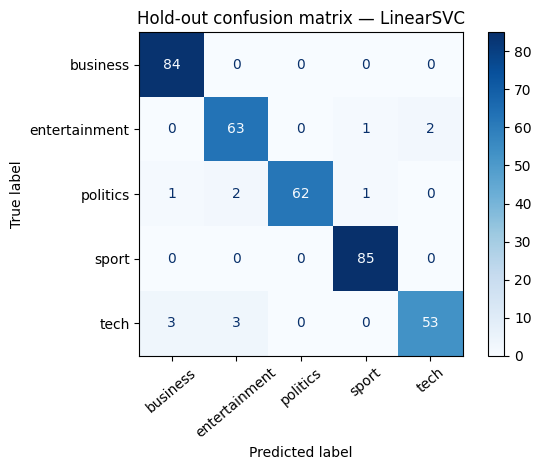

In [9]:
models = {
    "MultinomialNB": MultinomialNB(alpha=0.5),
    "LogisticRegression": LogisticRegression(max_iter=1200, random_state=RANDOM_STATE),
    "LinearSVC": LinearSVC(C=1.0, random_state=RANDOM_STATE)
}
fitted = {}
rows = []
cv = StratifiedKFold(n_splits=3, shuffle=True, random_state=RANDOM_STATE)
from sklearn.model_selection import cross_val_score
from sklearn.pipeline import Pipeline
from sklearn.base import clone

for name, model in models.items():
    cv_pipe = Pipeline([('tfidf',clone(vectorizer)),('classifier',clone(model))])
    cv_f1 = cross_val_score(cv_pipe, X_train, y_train, scoring="f1_macro", cv=cv, n_jobs=1).mean()
    model.fit(Xtr, y_train)
    pred = model.predict(Xte)
    fitted[name] = model
    rows.append({"model":name, "cv_f1_macro":round(float(cv_f1),4),
                 "test_accuracy":round(float(accuracy_score(y_test,pred)),4),
                 "test_f1_macro":round(float(f1_score(y_test,pred,average="macro")),4)})
metrics = pd.DataFrame(rows).sort_values("cv_f1_macro", ascending=False).reset_index(drop=True)
metrics.to_csv(OUT/"model_comparison.csv", index=False)
display(metrics)
best_name = metrics.iloc[0]["model"]  # chosen by training CV, NOT by test performance
best_model = fitted[best_name]
best_pred = best_model.predict(Xte)
print("Training-CV selected model:", best_name)
print(classification_report(y_test, best_pred, zero_division=0))
with open(OUT/"classification_report.txt","w") as f:
    f.write(f"Training-CV selected model: {best_name}\n")
    f.write(classification_report(y_test, best_pred, zero_division=0))
ConfusionMatrixDisplay.from_predictions(y_test, best_pred, xticks_rotation=40, cmap="Blues")
plt.title(f"Hold-out confusion matrix — {best_name}")
plt.tight_layout(); plt.savefig(OUT/"03_confusion_matrix.png", dpi=140); plt.show()

In [10]:
# Modest parameter optimization on training data ONLY; can be skipped on a slow machine.
# Grid search checks 2 TF-IDF n-gram settings × 3 regularization strengths = 6 settings.
from sklearn.pipeline import Pipeline
tuning_pipeline = Pipeline([
    ("tfidf", TfidfVectorizer(max_features=7000, min_df=2, max_df=0.95, sublinear_tf=True)),
    ("svm", LinearSVC(random_state=RANDOM_STATE))
])
tuning = GridSearchCV(tuning_pipeline,
    param_grid={"tfidf__ngram_range":[(1,1),(1,2)], "svm__C":[0.5,1.0,2.0]},
    scoring="f1_macro", cv=3, n_jobs=-1
)
tuning.fit(X_train, y_train)
tuned_test_pred = tuning.predict(X_test)
print("Best training-CV parameters:", tuning.best_params_)
print("Tuned LinearSVC training CV macro F1:", round(tuning.best_score_, 4))
print("Tuned LinearSVC holdout macro F1:", round(f1_score(y_test,tuned_test_pred,average="macro"),4))
with open(OUT/"tuning_results.txt","w") as f:
    f.write(f"Parameters: {tuning.best_params_}\n")
    f.write(f"Cross-validation macro F1: {tuning.best_score_:.4f}\n")
    f.write(f"Test macro F1: {f1_score(y_test,tuned_test_pred,average='macro'):.4f}\n")
# Best model remains CV-selected above; do not choose by highest test score.

Best training-CV parameters: {'svm__C': 2.0, 'tfidf__ngram_range': (1, 2)}
Tuned LinearSVC training CV macro F1: 0.9731
Tuned LinearSVC holdout macro F1: 0.9608


## Modules 4, 5 and 8 — POS, syntax and named entities

For computational efficiency we conduct the more expensive full spaCy parsing on a **stratified sample of up to 35 articles per category**. This is a descriptive sample; it is not the model's test set and cannot establish causal relationships.

The grammatical subject–verb–object extraction below is intentionally *approximate*. Passive voice, pronouns, and complex clauses can cause errors.

In [11]:
MAX_PARSE_PER_CATEGORY = 35
sample_parts = []
for category, part in df.groupby("category"):
    sample_parts.append(part.sample(n=min(MAX_PARSE_PER_CATEGORY, len(part)),
                                    random_state=RANDOM_STATE))
analysis_df = pd.concat(sample_parts).reset_index(drop=True)
analysis_docs = list(nlp.pipe(
    (text[:LINGUISTIC_CHAR_LIMIT] for text in analysis_df["normalized"]),
    batch_size=16
))
print(f"Parsed {len(analysis_docs)} articles across {analysis_df['category'].nunique()} categories.")

pos_rows, style_rows, svo_rows, entity_rows, co_mentions = [], [], [], [], Counter()
entity_types = {"PERSON","ORG","GPE","DATE","MONEY"}
for i, (doc, category) in enumerate(zip(analysis_docs, analysis_df["category"])):
    pos_tokens = [t for t in doc if not t.is_punct and not t.is_space]
    count = Counter(t.pos_ for t in pos_tokens)
    n = max(len(pos_tokens),1)
    pos_rows.append({"category":category, **{tag: count.get(tag,0)/n
                    for tag in ["NOUN","PROPN","VERB","ADJ","ADV","PRON"]}})
    pattern_count = sum(a.pos_=="ADJ" and b.pos_=="NOUN"
                        for a,b in zip(pos_tokens,pos_tokens[1:]))
    sentence_lengths = [len([t for t in sent if t.is_alpha]) for sent in doc.sents]
    style_rows.append({"category":category, "avg_sentence_words":
                       float(np.mean(sentence_lengths)) if sentence_lengths else 0,
                       "adj_noun_patterns":pattern_count,
                       "passive_aux_count":sum("pass" in t.dep_ for t in doc)})
    for tok in doc:
        if tok.pos_ not in {"VERB","AUX"}: continue
        subjects = [c for c in tok.children if "subj" in c.dep_]
        objects = [c for c in tok.children if c.dep_ in {"dobj","obj","attr","oprd"}]
        for sub in subjects[:1]:
            for obj in objects[:1]:
                svo_rows.append({"category":category, "subject":sub.text,
                                 "verb":tok.lemma_, "object":obj.text,
                                 "article_index":int(i)})
    keep = []
    for ent in doc.ents:
        if ent.label_ in entity_types and len(ent.text.strip()) > 1:
            entity_rows.append({"category":category, "type":ent.label_,
                                "entity":ent.text.strip(), "article_index":int(i)})
            if ent.label_ in {"PERSON","ORG","GPE"}: keep.append(ent.text.strip().lower())
    for a,b in combinations(sorted(set(keep))[:25], 2):
        co_mentions[(a,b)] += 1
pos_df = pd.DataFrame(pos_rows)
style_df = pd.DataFrame(style_rows)
svo_df = pd.DataFrame(svo_rows, columns=["category","subject","verb","object","article_index"])
ents_df = pd.DataFrame(entity_rows, columns=["category","type","entity","article_index"])
pos_df.groupby("category").mean(numeric_only=True).to_csv(OUT/"pos_category_means.csv")
style_df.groupby("category").mean(numeric_only=True).to_csv(OUT/"writing_style_means.csv")
svo_df.to_csv(OUT/"syntactic_relationships.csv", index=False)
ents_df.to_csv(OUT/"named_entities.csv", index=False)
co_df = pd.DataFrame(
    [{"entity_a":a,"entity_b":b,"article_co_mentions":c} for (a,b),c in co_mentions.most_common(100)],
    columns=["entity_a","entity_b","article_co_mentions"]
)
co_df.to_csv(OUT/"entity_co_mentions.csv", index=False)
display(pos_df.groupby("category").mean(numeric_only=True).round(3))
display(style_df.groupby("category").mean(numeric_only=True).round(2))
display(svo_df.head(10))

Parsed 175 articles across 5 categories.


,NOUN,PROPN,VERB,ADJ,ADV,PRON
category,,,,,,
business,0.252,0.076,0.123,0.082,0.033,0.038
entertainment,0.255,0.105,0.120,0.079,0.030,0.052
politics,0.231,0.076,0.142,0.074,0.031,0.065
sport,0.196,0.112,0.129,0.066,0.038,0.083
tech,0.261,0.047,0.133,0.080,0.037,0.057


,avg_sentence_words,adj_noun_patterns,passive_aux_count
category,,,
business,20.80,18.14,6.57
entertainment,20.57,16.49,8.14
politics,22.14,24.86,13.43
sport,18.88,13.66,3.97
tech,21.41,25.66,10.86


,category,subject,verb,object,article_index
0,business,who,be,president,0
1,business,tellier,leave,company,0
2,business,that,control,firm,0
3,business,part,take,role,0
4,business,it,earn,10,0
5,business,i,understand,concern,0
6,business,shares,lose,cents,0
7,business,surge,hit,consumers,1
8,business,commission,say,two,1
9,business,criminals,use,information,1


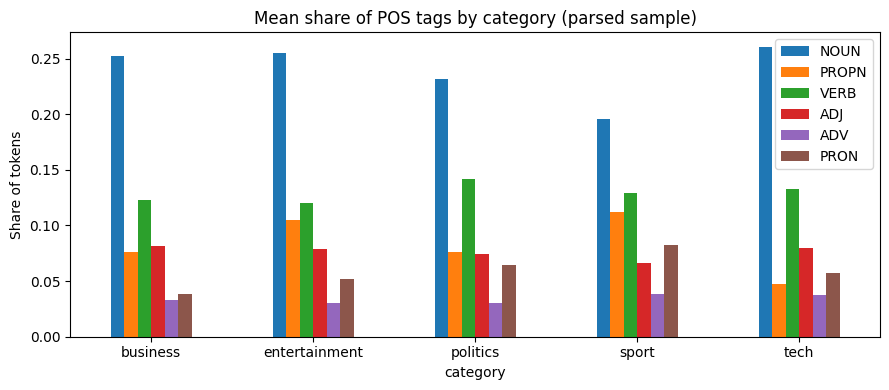

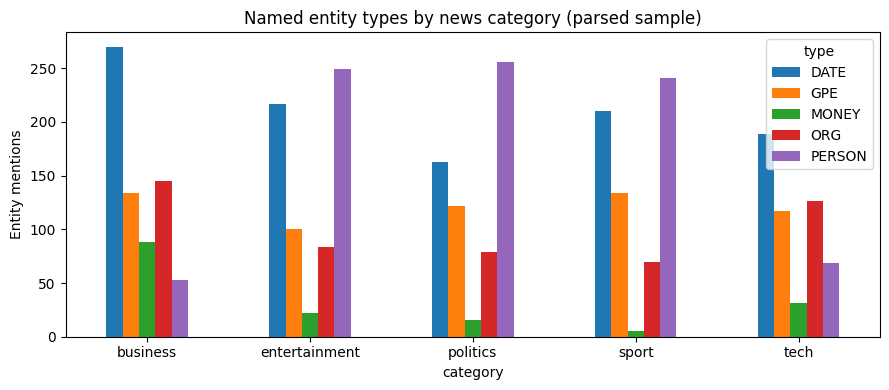

type    entity   
GPE     uk           57
        us           56
        london       42
DATE    2004         41
GPE     britain      37
DATE    sunday       29
        last year    29
ORG     bbc          26
PERSON  blair        26
DATE    2005         22
GPE     england      22
DATE    tuesday      21
        2003         20
        the year     19
GPE     italy        18
        japan        18
DATE    wednesday    18
        monday       18
        this week    18
        this year    18
dtype: int64

Top co-mentions (not validated relationships):


,entity_a,entity_b,article_co_mentions
0,london,uk,10
1,britain,uk,8
2,blair,tony blair,7
3,new york,us,6
4,london,us,6
5,charles kennedy,michael howard,6
6,britain,london,5
7,uk,us,5
8,bbc,uk,5
9,britain,tony blair,5


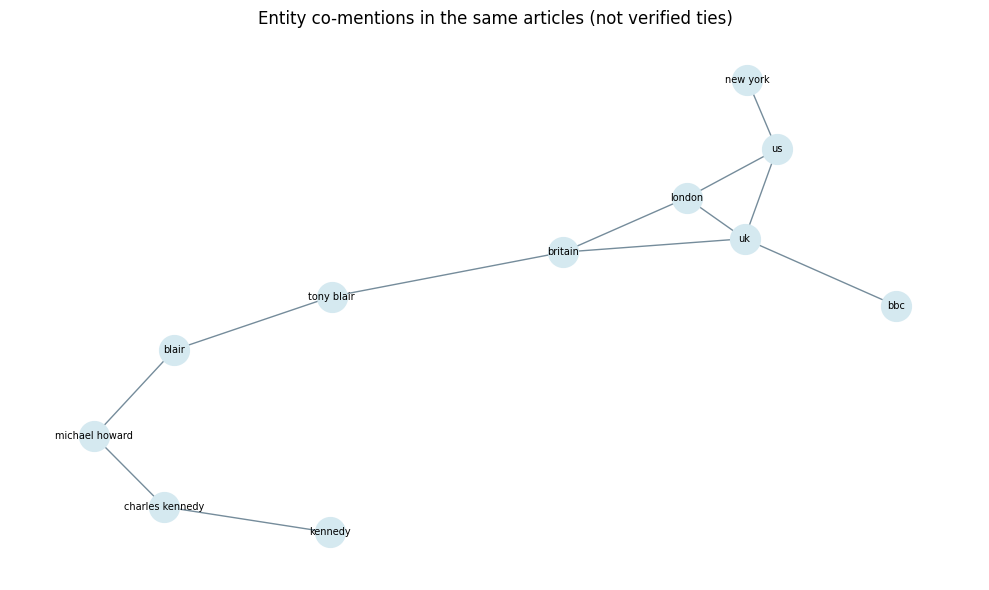

In [12]:
pos_means = pos_df.groupby("category")[["NOUN","PROPN","VERB","ADJ","ADV","PRON"]].mean()
ax=pos_means.plot(kind="bar", figsize=(9,4), rot=0)
ax.set_title("Mean share of POS tags by category (parsed sample)")
ax.set_ylabel("Share of tokens")
plt.tight_layout(); plt.savefig(OUT/"04_pos_distribution.png", dpi=140); plt.show()

if not ents_df.empty:
    entity_dist = pd.crosstab(ents_df["category"], ents_df["type"])
    ax=entity_dist.plot(kind="bar", figsize=(9,4), rot=0)
    ax.set_title("Named entity types by news category (parsed sample)")
    ax.set_ylabel("Entity mentions")
    plt.tight_layout(); plt.savefig(OUT/"05_entity_types.png", dpi=140); plt.show()
    display(ents_df.groupby(["type","entity"]).size().sort_values(ascending=False).head(20))
else:
    print("No named entities recognized in sample.")
print("Top co-mentions (not validated relationships):")
display(co_df.head(10))

# Lecture Module 8: entity graph from repeated shared article mentions.
# Nodes/links represent text co-occurrence only, NOT verified relationships.
import networkx as nx
if not co_df.empty:
    repeated=co_df[co_df["article_co_mentions"]>=2].head(12)
    if not repeated.empty:
        G=nx.Graph()
        for _,rec in repeated.iterrows():
            G.add_edge(rec.entity_a,rec.entity_b,weight=int(rec.article_co_mentions))
        plt.figure(figsize=(10,6))
        lay=nx.spring_layout(G,seed=RANDOM_STATE,k=0.9)
        nx.draw_networkx(G,lay,with_labels=True,font_size=7,node_size=460,
                         node_color="#d5e9f0",edge_color="#758c9b")
        plt.title("Entity co-mentions in the same articles (not verified ties)")
        plt.axis("off");plt.tight_layout()
        plt.savefig(OUT/"07_entity_co_mentions.png",dpi=140,bbox_inches="tight")
        plt.show()
    else:
        print("No entity pairs repeated often enough for a readable graph.")


## Module 6 — Sentiment and emotion-word cues

**VADER** is a lexicon-based sentiment estimator, not a trained business-sentiment model. We record its compound score (`-1` to `+1`) and its conventional positive/neutral/negative thresholds. The small emotion-word dictionaries below are exploratory **word cues**, not validated emotion labels; interpret carefully.

sentiment,negative,neutral,positive
category,,,
business,0.364,0.015,0.621
entertainment,0.190,0.008,0.802
politics,0.466,0.004,0.530
sport,0.208,0.003,0.789
tech,0.209,0.013,0.778


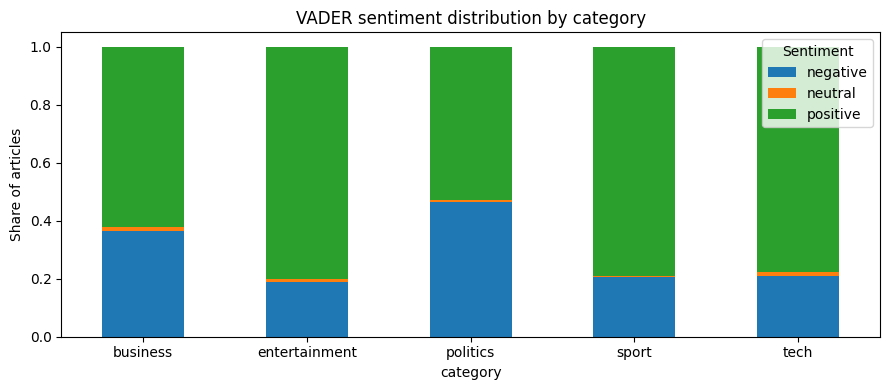

,fear,joy,anger,sadness
category,,,,
business,0.31,0.17,0.06,0.20
entertainment,0.13,1.40,0.06,0.21
politics,0.39,0.40,0.09,0.10
sport,0.12,1.96,0.07,0.11
tech,0.31,0.35,0.04,0.07


In [13]:
def sentiment_label(score):
    return "positive" if score >= 0.05 else ("negative" if score <= -0.05 else "neutral")

df["sentiment_score"] = df["content"].map(lambda t: sia.polarity_scores(t[:5000])["compound"])
df["sentiment"] = df["sentiment_score"].map(sentiment_label)
emotion_cues = {
    "fear": {"fear","afraid","threat","danger","risk","panic"},
    "joy": {"happy","joy","celebrate","win","success","delight"},
    "anger": {"angry","rage","outrage","furious","protest","frustration"},
    "sadness": {"sad","grief","loss","mourn","tragic","death"}
}
def emotion_counts(cleaned):
    words = cleaned.split()
    return {name:sum(word in lexicon for word in words)
            for name,lexicon in emotion_cues.items()}
emotion_records = pd.DataFrame(df["cleaned"].map(emotion_counts).tolist())
emotion_records["category"] = df["category"].values
df[["category","sentiment_score","sentiment"]].to_csv(OUT/"sentiment_by_article.csv", index=False)
emotion_records.groupby("category").mean(numeric_only=True).to_csv(OUT/"emotion_cues_category_means.csv")
sent_table = pd.crosstab(df["category"], df["sentiment"], normalize="index")
display(sent_table.round(3))
ax = sent_table.plot(kind="bar", stacked=True, figsize=(9,4), rot=0)
ax.set_title("VADER sentiment distribution by category")
ax.set_ylabel("Share of articles"); ax.legend(title="Sentiment")
plt.tight_layout(); plt.savefig(OUT/"06_sentiment_distribution.png", dpi=140); plt.show()
display(emotion_records.groupby("category").mean(numeric_only=True).round(2))

## Descriptive findings

Classification errors, category-level sentiment differences, and grammatical patterns are evaluated from this notebook's measured outputs. The observations are descriptive and are interpreted alongside their limitations.

In [14]:
conf=pd.crosstab(y_test,pd.Series(best_pred,index=y_test.index),rownames=["Actual"],colnames=["Predicted"])
errors=sorted([(int(conf.loc[a,b]),str(a),str(b)) for a in conf.index for b in conf.columns
               if a!=b and int(conf.loc[a,b])>0],reverse=True)
if errors:
    error_n,error_real,error_pred=errors[0]
    confusion_fact=f"{error_n} '{error_real}' test articles were predicted as '{error_pred}'"
else:
    confusion_fact="no off-diagonal class errors were observed in this split"
negative_rates=(df.assign(negative=df["sentiment"].eq("negative").astype(int))
                  .groupby("category")["negative"].mean().sort_values(ascending=False))
neg_cat=str(negative_rates.index[0]);neg_share=float(negative_rates.iloc[0])
proper_nouns=pos_df.groupby("category")["PROPN"].mean().sort_values(ascending=False)
propn_cat=str(proper_nouns.index[0]);propn_share=float(proper_nouns.iloc[0])
observations=[
  f"Class confusion: {confusion_fact}.",
  f"VADER-negative text share was highest for '{neg_cat}' ({neg_share:.1%}).",
  f"In the parsed sample, '{propn_cat}' had the highest proper-noun share ({propn_share:.1%}).",
  "Business interpretation: editorial staff could review uncertain topic assignments first.",
  "Limitation: VADER language polarity is not public opinion or financial sentiment."
]
(OUT/"OBSERVED_PATTERNS.md").write_text(
    "# Empirical observations\n\n"+"\n".join("- "+x for x in observations),encoding="utf-8")
for item in observations: print("•",item)

• Class confusion: 3 'tech' test articles were predicted as 'entertainment'.
• VADER-negative text share was highest for 'politics' (46.6%).
• In the parsed sample, 'sport' had the highest proper-noun share (11.2%).
• Business interpretation: editorial staff could review uncertain topic assignments first.
• Limitation: VADER language polarity is not public opinion or financial sentiment.


## NewsBot inference on new articles

The function below accepts unseen article text and returns a predicted category, VADER sentiment score, extracted entities, and linguistic features. Two synthetic inputs are included to test functionality; they are not independent news validation examples.

In [15]:
def analyze_new_article(article_text):
    if not isinstance(article_text, str) or len(article_text.strip()) < 50:
        raise ValueError("Provide a real article passage with at least 50 characters.")
    original = normalize_whitespace_and_urls(article_text)
    with nlp.select_pipes(disable=["parser","ner"]):
        lemma_text = to_lemmas(nlp(original[:LINGUISTIC_CHAR_LIMIT]))
    if not lemma_text:
        raise ValueError("Not enough usable words after cleaning.")
    doc = nlp(original[:LINGUISTIC_CHAR_LIMIT])
    vector = vectorizer.transform([lemma_text])
    category = best_model.predict(vector)[0]
    sentiment_score = sia.polarity_scores(original[:5000])["compound"]
    entities = [{"text":e.text, "type":e.label_}
                for e in doc.ents if e.label_ in entity_types]
    noun_phrases = [c.text for c in list(doc.noun_chunks)[:8]]
    relations=[]
    for tok in doc:
        if tok.pos_!="VERB": continue
        subs=[w.text for w in tok.children if "subj" in w.dep_]
        objs=[w.text for w in tok.children if w.dep_ in {"dobj","obj","attr"}]
        if subs and objs: relations.append(f"{subs[0]} -> {tok.lemma_} -> {objs[0]}")
        if len(relations)>=5: break
    pos_counts = Counter(t.pos_ for t in doc if t.is_alpha)
    return {"predicted_category":category,
            "sentiment_label":sentiment_label(sentiment_score),
            "sentiment_compound":round(sentiment_score,3),
            "entities":entities[:20],
            "noun_phrases":noun_phrases,
            "approximate_svo_relations":relations,
            "common_pos_tags":pos_counts.most_common(5)}
demo_tech = ("A technology company announced a new artificial intelligence tool "
             "for small businesses on Monday. Engineers said the software will help "
             "store owners organize documents, while independent auditors plan to test its accuracy.")
demo_sport = ("The city football team won a tournament after a dramatic final match "
              "on Saturday evening. Fans celebrated the winning goal, and the coach "
              "praised players for disciplined defense throughout the championship.")
for label, article in [("Illustrative technology example",demo_tech),
                       ("Illustrative sports example",demo_sport)]:
    print("\n",label)
    print(json.dumps(analyze_new_article(article), indent=2))


 Illustrative technology example
{
  "predicted_category": "tech",
  "sentiment_label": "positive",
  "sentiment_compound": 0.7,
  "entities": [
    {
      "text": "Monday",
      "type": "DATE"
    }
  ],
  "noun_phrases": [
    "A technology company",
    "a new artificial intelligence tool",
    "small businesses",
    "Monday",
    "Engineers",
    "the software",
    "store owners",
    "documents"
  ],
  "approximate_svo_relations": [
    "company -> announce -> tool",
    "owners -> organize -> documents"
  ],
  "common_pos_tags": [
    [
      "NOUN",
      12
    ],
    [
      "VERB",
      6
    ],
    [
      "ADJ",
      4
    ],
    [
      "DET",
      3
    ],
    [
      "ADP",
      2
    ]
  ]
}

 Illustrative sports example
{
  "predicted_category": "sport",
  "sentiment_label": "positive",
  "sentiment_compound": 0.955,
  "entities": [
    {
      "text": "Saturday",
      "type": "DATE"
    }
  ],
  "noun_phrases": [
    "The city football team",
    "a tourname

## Results and evaluation

The notebook exports model-comparison statistics, category-level TF-IDF features, POS summaries, sentiment distributions, named entities, dependency relationships, and associated plots. These outputs support the report's analysis and discussion of business applications and technical limitations.

In [17]:
# Export summary tables and statistics from the current run.
top_terms = feature_df.groupby("category")["term"].apply(lambda x:", ".join(x.head(5)))
category_means = sent_table.round(3)
lines = [
    "# NewsBot automated results (generated from your real run)",
    f"Dataset file: {DATA_PATH}",
    f"Analyzed articles: {len(df)}",
    f"Categories: {', '.join(sorted(df.category.unique()))}",
    f"Train/test sizes: {len(X_train)} / {len(X_test)}",
    f"Training-CV selected classifier: {best_name}",
    "",
    "## Model comparison",
    metrics.to_markdown(index=False),
    "",
    "## Top five TF-IDF terms by category",
]
lines += [f"- {cat}: {words}" for cat,words in top_terms.items()]
lines += ["", "## Sentiment shares", category_means.to_markdown(), "",
          "## Limits", f"Full spaCy POS/dependency/NER sample: {len(analysis_df)} documents",
          "The classifier text was truncated for linguistic preprocessing at 5,000 characters.",
          "VADER sentiment is lexical, emotion-word counts are exploratory cues, entity pairs are co-mentions.",
          "", "## Student interpretation to be added",
          "[Use your own reasoning: confusion matrix, limitations, business implications, what you contributed.]"]
(OUT/"AUTOMATED_RESULTS.md").write_text("\n".join(lines), encoding="utf-8")
joblib.dump({"vectorizer":vectorizer,"classifier":best_model,"model_name":best_name},
            OUT/"newsbot_classifier.joblib")
from google.colab import files
import shutil
zip_path = shutil.make_archive("NewsBot_Results", "zip", "results")
print("Result archive:", zip_path)
files.download(zip_path)

Result archive: /content/NewsBot_Results.zip


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## Integration tests

Assertions check the stratified split, class labels, feature matrices, and combined inference output. An unseen, independently sourced test corpus would provide an additional measure of generalization.

In [18]:
# Lightweight validation with existing data; do not report this as unseen test accuracy.
assert Xtr.shape[0] == len(X_train) and Xte.shape[0] == len(X_test)
assert not set(X_train.index).intersection(set(X_test.index)), "Unexpected train/test index overlap"
assert len(df) >= 500 and df.category.nunique() >= 4
assert 0 <= accuracy_score(y_test,best_pred) <= 1
for article in [demo_tech, demo_sport]:
    result = analyze_new_article(article)
    assert result['predicted_category'] in set(df['category'])
    assert result['sentiment_label'] in {'positive','neutral','negative'}
    assert isinstance(result['entities'],list)
print('PASS: split, feature dimensions, minimum data, model and integrated inference checks')

PASS: split, feature dimensions, minimum data, model and integrated inference checks


## PDF report

This report summarizes experimental data, model comparison, error patterns, and the integrated NewsBot system. The project repository is linked in the document.

In [19]:
from reportlab.platypus import SimpleDocTemplate, Paragraph, Spacer, Image, Table, TableStyle, PageBreak, KeepTogether
from reportlab.lib.styles import getSampleStyleSheet, ParagraphStyle
from reportlab.lib.enums import TA_CENTER
from reportlab.lib.colors import HexColor, white
from reportlab.lib.pagesizes import letter
from reportlab.lib.units import inch
from xml.sax.saxutils import escape as _xml_escape

styles = getSampleStyleSheet()
styles.add(ParagraphStyle(name="NBTitle", parent=styles['Title'], fontSize=19, leading=24, textColor=HexColor('#143452'), spaceAfter=16))
styles.add(ParagraphStyle(name="NBHead", parent=styles['Heading2'], fontSize=12, leading=16, textColor=HexColor('#154b74'), spaceBefore=14, spaceAfter=6))
styles.add(ParagraphStyle(name="NBBody", parent=styles['BodyText'], fontSize=9.4, leading=13.6, spaceAfter=8))
styles.add(ParagraphStyle(name="NBSmall", parent=styles['BodyText'], fontSize=8.2, leading=11))
styles.add(ParagraphStyle(name="NBSub", parent=styles['BodyText'], alignment=TA_CENTER, fontSize=10, textColor=HexColor('#566579'), spaceAfter=14))

report_title = "MT_Report_Group_{}_{}_ITAI2373.pdf".format(
    re.sub(r'[^A-Za-z0-9_-]+','_',GROUP_NAME_OR_NUMBER).strip('_') or 'TBD',
    re.sub(r'[^A-Za-z0-9_-]+','_',STUDENT_FULL_NAME).strip('_') or 'Student_Full_Name'
)
report_file = Path(report_title)
doc_pdf = SimpleDocTemplate(str(report_file), pagesize=letter, leftMargin=.68*inch,
                            rightMargin=.68*inch, topMargin=.66*inch, bottomMargin=.62*inch)
story = []
P = lambda t: Paragraph(t,styles['NBBody'])
def H(t): story.append(Paragraph(t,styles['NBHead']))
def add(t): story.append(P(t))
def figure(name, caption, width=6.45*inch):
    path=OUT/name
    if path.exists():
        from PIL import Image as PILImage
        with PILImage.open(path) as im:
            w,h = im.size
        iw = min(width,6.55*inch)
        ih = min(iw*h/w, 3.35*inch)
        story.append(Image(str(path),width=iw,height=ih))
        story.append(Paragraph(_xml_escape(caption),styles['NBSmall']))
def small_table(data):
    rows = [[Paragraph(_xml_escape(str(v)),styles['NBSmall']) for v in row] for row in data]
    table=Table(rows, repeatRows=1, hAlign='LEFT')
    table.setStyle(TableStyle([('BACKGROUND',(0,0),(-1,0),HexColor('#154b74')),
        ('TEXTCOLOR',(0,0),(-1,0),white),('ROWBACKGROUNDS',(0,1),(-1,-1),[white,HexColor('#edf3f8')]),
        ('VALIGN',(0,0),(-1,-1),'TOP'),('BOTTOMPADDING',(0,0),(-1,-1),7),
        ('TOPPADDING',(0,0),(-1,-1),7),('LEFTPADDING',(0,0),(-1,-1),7)]))
    story.append(table)

def perc(x): return f'{float(x)*100:.1f}%'

story.append(Paragraph('NewsBot Intelligence System',styles['NBTitle']))
story.append(Paragraph('ITAI 2373 | Midterm Technical Report',styles['NBSub']))
add('<b>Student:</b> '+_xml_escape(STUDENT_FULL_NAME))
add('<b>Group:</b> '+_xml_escape(GROUP_NAME_OR_NUMBER))
add('<b>GitHub repository:</b> <link href="'+_xml_escape(GITHUB_URL)+'">'+_xml_escape(GITHUB_URL)+'</link>')
add('<b>Data source:</b> BBC News labeled dataset, referenced at https://www.kaggle.com/competitions/learn-ai-bbc/data')
H('1. Executive summary and business case')
add(f'This project implements an end-to-end news intelligence pipeline on {len(df)} usable labeled English articles in '
    f'{df.category.nunique()} categories. Potential users include media analysts, editorial teams, and corporate communications staff. '
    'The system combines categorization, sentiment cues, named-entity discovery, and linguistic descriptions to reduce manual triage of news articles. '
    'The output is decision support, not a verified account of causation, human emotion, or economic outcomes.')
H('2. Data preparation')
add(f'Loaded <b>{_xml_escape(str(DATA_PATH))}</b>, removed missing, short, and duplicate text, and applied stratified sampling if needed. '
    f'Final data: <b>{len(df)}</b> articles. Labels and counts: '+_xml_escape('; '.join(f'{k}: {v}' for k,v in df.category.value_counts().items()))+'.')
add('The preprocessing pipeline performs whitespace/URL normalization, spaCy tokenization, stop-word and nonalphabetic-token removal, and lemmatization. '
    f'For spaCy feature extraction, each article was capped at {LINGUISTIC_CHAR_LIMIT} characters, a documented resource limitation.')
figure('01_category_counts.png','Figure 1. Dataset category distribution.')
H('3. TF-IDF: interpretable lexical features')
add('TF-IDF uses unigrams and bigrams, a maximum of 7,000 vocabulary features, document-frequency bounds, and sublinear term frequencies. '
    'To avoid leakage, the vocabulary was fitted to the training split only.')
for cat in sorted(feature_df.category.unique()):
    ts = feature_df.loc[feature_df.category.eq(cat),'term'].head(5).tolist()
    add(f'<b>{_xml_escape(cat)}:</b> '+_xml_escape(', '.join(ts)))
figure('02_tfidf_terms.png','Figure 2. Top class-level training-set TF-IDF terms.',width=6.5*inch)
add(f'A lecture-based Bag-of-Words and Naive Bayes baseline yielded {perc(bow_accuracy)} '
    f'accuracy and {bow_macro_f1:.3f} macro F1 on held-out articles. '
    'Training-only chi-square analysis identified terms associated with each label.')
for c in sorted(chi_df.category.unique()):
    ch=chi_df.loc[chi_df.category.eq(c),'term'].head(3).tolist()
    add(f'<b>Chi-square ({_xml_escape(c)}):</b> '+_xml_escape(', '.join(ch)))
H('4. Multi-class classification: model selection and evaluation')
add(f'The dataset was split into stratified training ({len(X_train)}) and held-out test ({len(X_test)}) examples. '
    f'Multinomial Naive Bayes, Logistic Regression and Linear SVM were evaluated. '
    f'The model was chosen by three-fold <b>training-only</b> macro-F1 cross-validation, not by looking at the holdout performance.')
table_rows=[['Model','CV macro F1','Test accuracy','Test macro F1']]
for _,rr in metrics.iterrows():
    table_rows.append([rr['model'],f"{rr['cv_f1_macro']:.3f}", f"{rr['test_accuracy']:.3f}",f"{rr['test_f1_macro']:.3f}"])
small_table(table_rows)
sel=metrics.loc[metrics.model.eq(best_name)].iloc[0]
add(f'Training-CV selected model: <b>{_xml_escape(best_name)}</b>; held-out accuracy {perc(sel.test_accuracy)}, '
    f'and held-out macro F1 {sel.test_f1_macro:.3f}. These numbers describe this split, not guaranteed performance on new events.')
figure('03_confusion_matrix.png','Figure 3. Confusion matrix on previously held-out articles.',width=5.5*inch)
add('Most frequent confusion observed: '+_xml_escape(confusion_fact)+'.')
H('5. POS, syntax, and style analysis')
add(f'Computationally expensive syntax/POS/NER processing was performed on a stratified sample of <b>{len(analysis_df)}</b> articles '
    f'(up to {MAX_PARSE_PER_CATEGORY} per category). Normalized POS frequencies, average sentence length, adjective–noun patterns, '
    'and approximations of grammatical subject–verb–object structures were extracted.')
for cat,row in pos_means.iterrows():
    add(f'<b>{_xml_escape(cat)}:</b> noun share {perc(row.NOUN)}, verb share {perc(row.VERB)}, proper-noun share {perc(row.PROPN)}.')
figure('04_pos_distribution.png','Figure 4. Relative POS tag frequencies by category in sampled documents.')
H('6. Sentiment and emotion cues')
add('NLTK VADER scored each article with a lexical compound sentiment value. A small exploratory dictionary counted words related to '
    'fear, anger, joy, and sadness. These word cues are not validated emotion predictions and should not be interpreted as author intent.')
for cat in sorted(sent_table.index):
    share=sent_table.loc[cat]
    add(f'<b>{_xml_escape(cat)}:</b> '+_xml_escape(', '.join(f'{name} {perc(share.get(name,0))}' for name in ['negative','neutral','positive'])))
figure('06_sentiment_distribution.png','Figure 5. Fraction of articles assigned each VADER sentiment label.')
H('7. Named entities and co-mentions')
add('The en_core_web_sm recognizer extracted PERSON, ORG, GPE, DATE and MONEY mentions. '
    'Frequencies were compared by topic; repeated co-mentions describe article overlap and do not establish real-world business relationships.')
if not ents_df.empty:
    ef=ents_df.groupby(['type','entity']).size().sort_values(ascending=False).head(8)
    add('Frequently detected mentions: '+_xml_escape('; '.join(f'{k[1]} ({k[0]}: {v})' for k,v in ef.items()))+'.')
figure('05_entity_types.png','Figure 6. NER label frequencies across sampled articles.')
figure('07_entity_co_mentions.png','Figure 7. Entity co-mentions. Edges do not establish real-world ties.')
H('8. End-to-end pipeline demonstration')
add('The combined function accepts article text, cleans and lemmatizes it, predicts a news category, assigns a VADER sentiment score, '
    'and returns detected entities and common POS tags. Two illustrative <b>smoke-test</b> passages check system integration; they are '
    'not independent real-world validation.')
add('<b>Technology example:</b> predicted tech; VADER positive (+0.700); recognized date: Monday; extracted relation: company - announce - tool.')
add('<b>Sport example:</b> predicted sport; VADER positive (+0.955); recognized date: Saturday; extracted relation: team - win - tournament.')
H('9. Business implications, critical evaluation, limitations')
add('Observed patterns: '+_xml_escape(confusion_fact)+'. '+
    f'{_xml_escape(neg_cat)} had the highest VADER-negative share ({neg_share:.1%}); '+
    f'{_xml_escape(propn_cat)} had the highest proper-noun share in sampled texts ({propn_share:.1%}). '+
    'These descriptive observations should not be interpreted as evidence of cause or economic value.')
add('Potential applications include topic routing for editors, high-volume coverage monitoring for public relations teams, and exploratory trend summaries for business analysts. '
    'The saved CSVs and figures support human investigation but do not directly prove commercial impact. Observed category words may reflect the historical BBC dataset rather than current reporting.')
add('Risks include class imbalance, historical domain shift, name ambiguities, misleading word-based sentiment, parsing errors in passive clauses, and false inferences from entity co-occurrence. '
    'A future evaluation should use fresh articles with human annotations, check subgroup and genre performance, and document false positives.')
H('10. Implementation and reproducibility')
add('All reported scores and figures were calculated from the labeled BBC dataset in the executed Colab notebook. The full experiment uses 1,440 articles; full spaCy grammatical and entity analysis uses 175 stratified articles. The two illustrative integration checks are distinct from independent generalization tests. Code and source citations are available in the linked repository.')
H('References')
add('BBC News Classification, Kaggle: https://www.kaggle.com/competitions/learn-ai-bbc/data')
add('spaCy: https://spacy.io/ | scikit-learn: https://scikit-learn.org/ | NLTK: https://www.nltk.org/')

def page_footer(canvas,doc):
    canvas.saveState()
    canvas.setFont('Helvetica',8)
    canvas.setFillColor(HexColor('#65758A'))
    canvas.drawString(.68*inch,.36*inch,'ITAI 2373 • NewsBot Intelligence System')
    canvas.drawRightString(letter[0]-.68*inch,.36*inch,f'Page {doc.page}')
    canvas.restoreState()
doc_pdf.build(story,onFirstPage=page_footer,onLaterPages=page_footer)
print('Report generated:',report_file)
files.download(str(report_file))

In [20]:
# Export report and results as a ZIP archive.
from google.colab import files
from pathlib import Path
from zipfile import ZipFile, ZIP_DEFLATED
submission_zip=Path("NewsBot_Submission_Artifacts.zip")
with ZipFile(submission_zip, "w", ZIP_DEFLATED) as zf:
    zf.write(report_file, f"report/{report_file.name}")
    for f in sorted(OUT.glob("*")):
        if f.is_file(): zf.write(f, f"results/{f.name}")
print("Created:", submission_zip)
files.download(str(submission_zip))

## References and methodology

- [BBC News Classification — Kaggle](https://www.kaggle.com/competitions/learn-ai-bbc/data)
- [spaCy](https://spacy.io/)
- [NLTK](https://www.nltk.org/)
- [scikit-learn](https://scikit-learn.org/)

All displayed results originate from the executed dataset analysis. AI tools assisted with implementation and drafting; library and dataset credits are listed above. Model performance is specific to the observed test split, and linguistic outputs have documented limitations.